# Entrenamiento y comparación de modelos de clasificación de reseñas

**Proyecto 2 — Inteligencia Artificial | Firewatch**

**Objetivo:** predecir `voted_up` a partir del texto `review`. Se implementan un baseline trivial, uno simple y tres modelos adicionales; se realiza búsqueda de hiperparámetros con validación cruzada y evaluación final en un conjunto de prueba reservado.

## 1. Librerías y configuración
Para instalar las dependencias necesarias hay que ejecutar en una terminal: `pip install pandas numpy scikit-learn matplotlib seaborn`

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay)

RANDOM_STATE = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
sns.set_theme(style="whitegrid")

## 2. Carga y preparación de datos
Se usan exclusivamente `review` y `voted_up`. La columna `review_type` del análisis exploratorio no se utiliza, pues no representa la etiqueta final de este experimento.

In [2]:
candidates = [Path("../data/firewatch_reviews.csv"), Path("data/firewatch_reviews.csv")]
file_path = next((p for p in candidates if p.exists()), None)
if file_path is None:
    raise FileNotFoundError("No se encontró data/firewatch_reviews.csv. Ejecuta desde notebooks/ o desde la raíz del proyecto.")
df = pd.read_csv(file_path, low_memory=False)
print("Dimensiones originales:", df.shape)
assert {'review', 'voted_up'}.issubset(df.columns), "El CSV debe contener review y voted_up"
print(df[['review', 'voted_up']].head())

Dimensiones originales: (57067, 34)
                                              review  voted_up
0  The story and dialogues were easily my favorit...      True
1                              Goog game. Nuff said.      True
2  A heartbreaking reflection on the nature of li...      True
3  TL;DR: Firewatch is a beautiful, short narrati...      True
4  A very emotional short story. My first round t...      True


In [3]:
data = df[['review', 'voted_up']].copy()
data = data.dropna(subset=['review', 'voted_up'])
data['review'] = data['review'].astype(str).str.strip()
data = data[data['review'].str.len() > 0]

# Normalización segura de etiquetas booleanas (incluye cadenas y 0/1).
label_map = {'true': 1, 'false': 0, '1': 1, '0': 0}
data['target'] = data['voted_up'].astype(str).str.strip().str.lower().map(label_map)
if data['target'].isna().any():
    raise ValueError(f"Valores inesperados en voted_up: {data.loc[data.target.isna(), 'voted_up'].unique()}")
data['target'] = data['target'].astype(int)

# Evitar que el mismo texto aparezca en entrenamiento y prueba.
# Si el mismo texto tiene etiquetas contradictorias, se elimina por ambigüedad.
conflict = data.groupby('review')['target'].nunique()
conflicting_reviews = set(conflict[conflict > 1].index)
print('Textos con etiquetas contradictorias excluidos:', len(conflicting_reviews))
data = data[~data['review'].isin(conflicting_reviews)].drop_duplicates(subset=['review'])
print('Reseñas únicas utilizables:', len(data))
print('Distribución de clases:')
print(data['target'].value_counts(normalize=True).rename(index={0:'Negativa',1:'Positiva'}).round(3))
assert data['target'].nunique() == 2, 'Se requieren ambas clases para clasificación binaria.' 

Textos con etiquetas contradictorias excluidos: 29
Reseñas únicas utilizables: 52872
Distribución de clases:
target
Positiva    0.886
Negativa    0.114
Name: proportion, dtype: float64


## 3. División entrenamiento/prueba
El conjunto de prueba no se utiliza durante la búsqueda de hiperparámetros. TF-IDF se ajusta dentro de cada pliegue de validación mediante `Pipeline`, para evitar fuga de información.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    data['review'], data['target'], test_size=0.20,
    random_state=RANDOM_STATE, stratify=data['target'])
print(f'Entrenamiento: {len(X_train):,} | Prueba: {len(X_test):,}')
print('Proporciones entrenamiento:', y_train.value_counts(normalize=True).sort_index().round(3).to_dict())
print('Proporciones prueba:', y_test.value_counts(normalize=True).sort_index().round(3).to_dict())
if y_train.value_counts().min() < 5:
    raise ValueError('Se necesitan al menos 5 ejemplos de cada clase en entrenamiento para CV de 5 pliegues.')

Entrenamiento: 42,297 | Prueba: 10,575
Proporciones entrenamiento: {0: 0.114, 1: 0.886}
Proporciones prueba: {0: 0.114, 1: 0.886}


## 4. Baselines y modelos iniciales
Se comparan cinco enfoques. Para evitar que el desbalance oculte errores en reseñas negativas, la métrica principal de selección será **F1 macro**. También reportamos F1 para la clase negativa.

In [5]:
def make_pipeline(model):
    return Pipeline([
        ('tfidf', TfidfVectorizer(lowercase=True, strip_accents='unicode', ngram_range=(1, 1), min_df=2, max_features=20000, sublinear_tf=True)),
        ('clf', model)
    ])

models = {
    'Dummy (mayoritaria)': make_pipeline(DummyClassifier(strategy='most_frequent')),
    'Regresión logística': make_pipeline(LogisticRegression(max_iter=1500, class_weight='balanced', random_state=RANDOM_STATE)),
    'Naive Bayes': make_pipeline(MultinomialNB()),
    'SVM lineal': make_pipeline(LinearSVC(class_weight='balanced', random_state=RANDOM_STATE, max_iter=5000)),
    'Random Forest': make_pipeline(RandomForestClassifier(n_estimators=150, min_samples_leaf=2, class_weight='balanced_subsample', random_state=RANDOM_STATE, n_jobs=-1))
}

def evaluate(name, fitted_model, X, y, stage):
    pred = fitted_model.predict(X)
    return {'Etapa': stage, 'Modelo': name,
            'Accuracy': accuracy_score(y, pred),
            'Precision macro': precision_score(y, pred, average='macro', zero_division=0),
            'Recall macro': recall_score(y, pred, average='macro', zero_division=0),
            'F1 macro': f1_score(y, pred, average='macro', zero_division=0),
            'F1 negativa': f1_score(y, pred, pos_label=0, zero_division=0)}

### 4.1 Comparación inicial mediante validación cruzada
No se consulta el conjunto de prueba para seleccionar modelos. La siguiente celda puede tardar, especialmente Random Forest.

In [6]:
from sklearn.model_selection import cross_validate
baseline_cv_rows = []
for name, pipeline in models.items():
    scores = cross_validate(pipeline, X_train, y_train, cv=CV, scoring={'f1_macro':'f1_macro', 'accuracy':'accuracy'}, 
                            n_jobs=1, error_score='raise')
    baseline_cv_rows.append({'Modelo':name,
                            'F1 macro CV (media)':scores['test_f1_macro'].mean(),
                            'F1 macro CV (desv.)':scores['test_f1_macro'].std(),
                            'Accuracy CV (media)':scores['test_accuracy'].mean()})
cv_results = pd.DataFrame(baseline_cv_rows).sort_values('F1 macro CV (media)', ascending=False)
display(cv_results.round(4))

,Modelo,F1 macro CV (media),F1 macro CV (desv.),Accuracy CV (media)
3,SVM lineal,0.8078,0.0039,0.9099
1,Regresión logística,0.8010,0.0056,0.8999
4,Random Forest,0.7072,0.0128,0.9130
2,Naive Bayes,0.5348,0.0040,0.8921
0,Dummy (mayoritaria),0.4697,0.0000,0.8856


## 5. Búsqueda de hiperparámetros con validación cruzada
Se optimizan los **tres modelos adicionales** usando `GridSearchCV` y 5 pliegues estratificados. Cada combinación vuelve a ajustar TF-IDF dentro de sus pliegues. Las rejillas son deliberadamente moderadas para limitar el tiempo de cómputo; pueden ampliarse después.

In [7]:
search_spaces = {
    'Naive Bayes': {
        'tfidf__ngram_range': [(1, 1), (1, 2)],
        'clf__alpha': [0.1, 1.0, 5.0]
    },
    'SVM lineal': {
        'tfidf__ngram_range': [(1, 1), (1, 2)],
        'clf__C': [0.1, 1.0, 10.0]
    },
    'Random Forest': {
        'clf__n_estimators': [100, 200],
        'clf__max_depth': [20, None],
        'clf__min_samples_leaf': [1, 3]
    }
}

searches = {}
search_rows = []
for name, params in search_spaces.items():
    print(f'Buscando hiperparámetros: {name} ...')
    grid = GridSearchCV(
        estimator=models[name], param_grid=params,
        scoring='f1_macro', cv=CV, n_jobs=-1,
        refit=True, verbose=0, error_score='raise'
    )
    grid.fit(X_train, y_train)
    searches[name] = grid
    search_rows.append({'Modelo': name, 'Mejor F1 macro CV': grid.best_score_,
                        'Mejores parámetros': grid.best_params_})
search_results = pd.DataFrame(search_rows).sort_values('Mejor F1 macro CV', ascending=False)
display(search_results)

Buscando hiperparámetros: Naive Bayes ...
Buscando hiperparámetros: SVM lineal ...
Buscando hiperparámetros: Random Forest ...


,Modelo,Mejor F1 macro CV,Mejores parámetros
1,SVM lineal,0.839721,"{'clf__C': 1.0, 'tfidf__ngram_range': (1, 2)}"
0,Naive Bayes,0.797819,"{'clf__alpha': 0.1, 'tfidf__ngram_range': (1, 2)}"
2,Random Forest,0.761066,"{'clf__max_depth': None, 'clf__min_samples_lea..."


## 6. Selección del modelo y evaluación final
Para mantener una comparación justa, elegimos el mejor modelo por **F1 macro en CV**, considerando también los dos baselines. Solo después evaluamos los cinco modelos en el conjunto de prueba, sin modificar hiperparámetros en función de esos resultados.

In [8]:
# Los baselines se entrenan sobre todo el entrenamiento con sus parámetros fijos.
final_models = {}
for name in ['Dummy (mayoritaria)', 'Regresión logística']:
    final_models[name] = models[name].fit(X_train, y_train)
for name, grid in searches.items():
    final_models[name] = grid.best_estimator_

cv_scores = dict(zip(cv_results['Modelo'], cv_results['F1 macro CV (media)']))
cv_scores.update({name: grid.best_score_ for name, grid in searches.items()})
selected_name = max(cv_scores, key=cv_scores.get)
print('Modelo seleccionado según CV:', selected_name)
print('F1 macro de selección (CV):', round(cv_scores[selected_name], 4))

results = pd.DataFrame([
    evaluate(name, fitted, X_test, y_test, 'Prueba')
    for name, fitted in final_models.items()
]).sort_values('F1 macro', ascending=False)
display(results.round(4))

Modelo seleccionado según CV: SVM lineal
F1 macro de selección (CV): 0.8397


,Etapa,Modelo,Accuracy,Precision macro,Recall macro,F1 macro,F1 negativa
3,Prueba,SVM lineal,0.9353,0.8287,0.8829,0.8527,0.7425
1,Prueba,Regresión logística,0.9044,0.7671,0.8910,0.8102,0.6765
2,Prueba,Naive Bayes,0.9352,0.8928,0.7601,0.8087,0.6532
4,Prueba,Random Forest,0.9224,0.8440,0.7295,0.7714,0.5856
0,Prueba,Dummy (mayoritaria),0.8856,0.4428,0.5000,0.4697,0.0000


Reporte del modelo seleccionado: SVM lineal
              precision    recall  f1-score   support

    Negativa       0.68      0.81      0.74      1210
    Positiva       0.98      0.95      0.96      9365

    accuracy                           0.94     10575
   macro avg       0.83      0.88      0.85     10575
weighted avg       0.94      0.94      0.94     10575



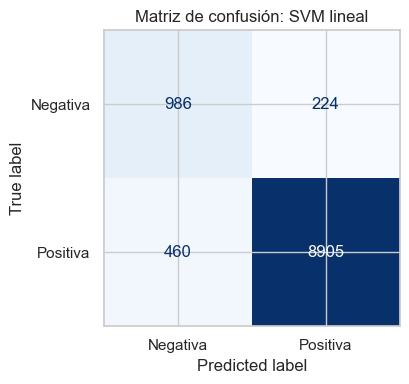

In [9]:
best_model = final_models[selected_name]
y_pred = best_model.predict(X_test)
print('Reporte del modelo seleccionado:', selected_name)
print(classification_report(y_test, y_pred, labels=[0,1],
                            target_names=['Negativa', 'Positiva'], zero_division=0))
fig, ax = plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=[0,1],
                                        display_labels=['Negativa','Positiva'],
                                        cmap='Blues', ax=ax, colorbar=False)
ax.set_title(f'Matriz de confusión: {selected_name}')
plt.tight_layout()
plt.show()

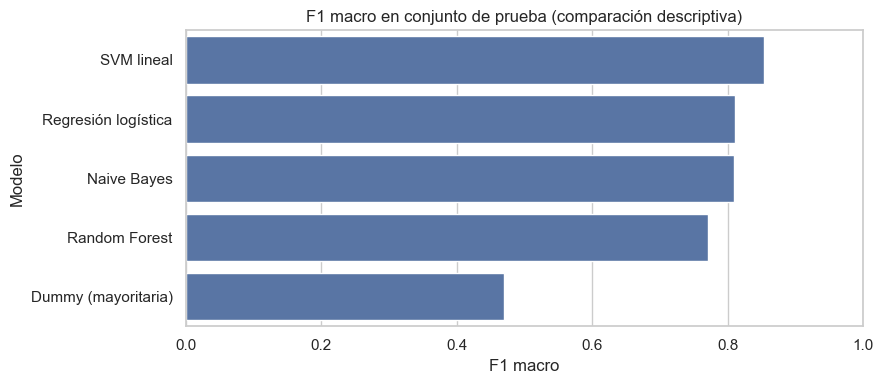

In [10]:
fig, ax = plt.subplots(figsize=(9,4))
sns.barplot(data=results, x='F1 macro', y='Modelo', ax=ax)
ax.set(xlim=(0,1), title='F1 macro en conjunto de prueba (comparación descriptiva)')
plt.tight_layout()
plt.show()